In [21]:
import pandas as pd

# 1. Definir las rutas a los archivos Excel
ruta_train = '../data/raw/entrenamiento_precios_vivienda.xlsx'
ruta_test = '../data/raw/testeo_precios_vivienda.xlsx'

# 2. Cargar los datos
df_train = pd.read_excel(ruta_train)
df_test = pd.read_excel(ruta_test)

# 3. Verificación de dimensiones
print("--- Dimensiones de los Datasets ---")
print(f"Entrenamiento: {df_train.shape[0]} filas, {df_train.shape[1]} columnas")
print(f"Prueba: {df_test.shape[0]} filas, {df_test.shape[1]} columnas")

# 4. Identificar columnas exclusivas en entrenamiento (posible fuga de datos o variable objetivo)
columnas_exclusivas = set(df_train.columns) - set(df_test.columns)
print(f"\n--- Columnas exclusivas en Entrenamiento ({len(columnas_exclusivas)}) ---")
print(list(columnas_exclusivas))

--- Dimensiones de los Datasets ---
Entrenamiento: 12857 filas, 221 columnas
Prueba: 5385 filas, 211 columnas

--- Columnas exclusivas en Entrenamiento (10) ---
['valor_area_terreno', 'valor_area_deposito', 'valor_avaluo_en_uvr', 'valor_area_libre', 'valor_area_otros', 'valor_area_construccion', 'valor_area_privada', 'valor_total_avaluo', 'valor_uvr', 'valor_area_garaje']


In [22]:
# 1. Definir la variable objetivo
target = 'valor_total_avaluo'

# 2. Separar las columnas a eliminar para evitar fuga de información
columnas_a_eliminar = list(columnas_exclusivas)
columnas_a_eliminar.remove(target) # Mantenemos el target, eliminamos el resto

# 3. Limpiar el dataset de entrenamiento
df_train_clean = df_train.drop(columns=columnas_a_eliminar)

print(f"--- Nuevas Dimensiones ---")
print(f"Entrenamiento limpio: {df_train_clean.shape[0]} filas, {df_train_clean.shape[1]} columnas")
print(f"Prueba: {df_test.shape[0]} filas, {df_test.shape[1]} columnas")

# 4. Exploración matemática del precio de las viviendas
print(f"\n--- Resumen estadístico de '{target}' ---")
# Configuramos Pandas para que no use notación científica y muestre los números con comas
pd.options.display.float_format = '{:,.2f}'.format 
print(df_train_clean[target].describe())

# 5. Inventario de datos faltantes (Nulos)
print("\n--- Top 15 columnas con más nulos (Datos Faltantes) ---")
nulos = df_train_clean.isnull().sum()
porcentaje_nulos = (nulos / len(df_train_clean)) * 100
df_nulos = pd.DataFrame({'Nulos': nulos, 'Porcentaje (%)': porcentaje_nulos})

# Mostramos solo las que tienen nulos, ordenadas de mayor a menor
top_nulos = df_nulos[df_nulos['Nulos'] > 0].sort_values(by='Porcentaje (%)', ascending=False).head(15)
print(top_nulos)

--- Nuevas Dimensiones ---
Entrenamiento limpio: 12857 filas, 212 columnas
Prueba: 5385 filas, 211 columnas

--- Resumen estadístico de 'valor_total_avaluo' ---
count     12857
unique    12298
top           0
freq        160
Name: valor_total_avaluo, dtype: object

--- Top 15 columnas con más nulos (Datos Faltantes) ---
                                      Nulos  Porcentaje (%)
tipo_subsidio                         11364           88.39
fecha_aprobación                       7513           58.44
descripcion_uso_inmueble                245            1.91
descripcion_tipo_inmueble               237            1.84
descripcion_clase_inmueble              237            1.84
numero_garaje_1                          28            0.22
observaciones_generales_construccion     20            0.16
barrio                                    6            0.05
numero_garaje_2                           4            0.03
matricula_inmobiliaria_deposito_3         2            0.02
Latitud           

In [23]:
# 1. Limpiar la variable objetivo (Target)
# Convertir a formato numérico puro. Si hay texto irreconocible, lo convierte a nulo (NaN)
df_train_clean['valor_total_avaluo'] = pd.to_numeric(df_train_clean['valor_total_avaluo'], errors='coerce')

# Eliminar las filas donde el precio es 0 o es nulo (no podemos enseñar a predecir con precios falsos)
df_train_clean = df_train_clean[df_train_clean['valor_total_avaluo'] > 0]

# 2. Eliminar columnas con demasiados nulos (más del 50%)
umbral = 50.0
# Usamos el dataframe 'df_nulos' que creamos en la celda anterior
columnas_con_muchos_nulos = df_nulos[df_nulos['Porcentaje (%)'] > umbral].index.tolist()
df_train_clean = df_train_clean.drop(columns=columnas_con_muchos_nulos)

print("--- Limpieza Fase 1 Completada ---")
print(f"Columnas eliminadas por exceso de nulos: {columnas_con_muchos_nulos}")
print(f"Dimensiones de entrenamiento actualizadas: {df_train_clean.shape[0]} filas, {df_train_clean.shape[1]} columnas")

print(f"\n--- Resumen estadístico del precio de las viviendas (Corregido) ---")
print(df_train_clean['valor_total_avaluo'].describe())

--- Limpieza Fase 1 Completada ---
Columnas eliminadas por exceso de nulos: ['fecha_aprobación', 'tipo_subsidio']
Dimensiones de entrenamiento actualizadas: 9249 filas, 210 columnas

--- Resumen estadístico del precio de las viviendas (Corregido) ---
count               9,249.00
mean        3,204,044,392.15
std        93,323,903,565.52
min                     3.00
25%           116,001,400.00
50%           177,526,400.00
75%           292,314,000.00
max     5,744,320,000,008.00
Name: valor_total_avaluo, dtype: float64


In [24]:
%pip install seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


--- Filtro de Valores Atípicos ---
Límite inferior (1%): $47,005,200.00
Límite superior (99%): $1,445,488,052.00
Filas antes del filtro: 9249
Filas después del filtro: 9063


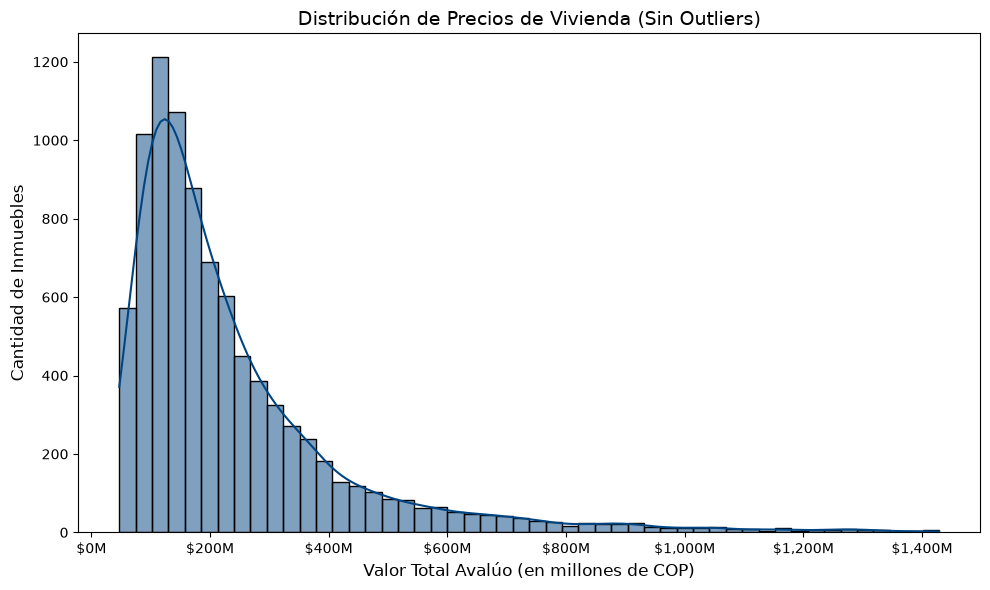

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Definir límites estadísticos (percentil 1 y 99)
limite_inferior = df_train_clean['valor_total_avaluo'].quantile(0.01)
limite_superior = df_train_clean['valor_total_avaluo'].quantile(0.99)

print(f"--- Filtro de Valores Atípicos ---")
print(f"Límite inferior (1%): ${limite_inferior:,.2f}")
print(f"Límite superior (99%): ${limite_superior:,.2f}")

# 2. Filtrar el dataset para mantener solo precios realistas
df_train_filtrado = df_train_clean[(df_train_clean['valor_total_avaluo'] >= limite_inferior) & 
                                   (df_train_clean['valor_total_avaluo'] <= limite_superior)]

print(f"Filas antes del filtro: {df_train_clean.shape[0]}")
print(f"Filas después del filtro: {df_train_filtrado.shape[0]}")

# 3. Graficar la distribución de precios
plt.figure(figsize=(10, 6))
sns.histplot(df_train_filtrado['valor_total_avaluo'], bins=50, kde=True, color='#004481') # Azul estilo Bancolombia
plt.title('Distribución de Precios de Vivienda (Sin Outliers)', fontsize=14)
plt.xlabel('Valor Total Avalúo (en millones de COP)', fontsize=12)
plt.ylabel('Cantidad de Inmuebles', fontsize=12)

# Formatear el eje X para leerlo en millones
ticks = plt.gca().get_xticks()
plt.gca().set_xticklabels([f'${x/1e6:,.0f}M' for x in ticks])
plt.tight_layout()
plt.show()

In [26]:
# 1. Separar variables por su tipo de dato
num_cols = df_train_filtrado.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_train_filtrado.select_dtypes(include=['object']).columns.tolist()

# Sacamos la variable objetivo de la lista de numéricas para no alterarla accidentalmente después
if 'valor_total_avaluo' in num_cols:
    num_cols.remove('valor_total_avaluo')

print(f"--- Inventario de Variables ---")
print(f"Variables numéricas puras: {len(num_cols)}")
print(f"Variables categóricas (texto): {len(cat_cols)}")

# 2. Explorar la cardinalidad de las categóricas (cuántas opciones diferentes tiene cada columna de texto)
print("\n--- Top 10 variables de texto con más categorías únicas ---")
cardinalidad = df_train_filtrado[cat_cols].nunique().sort_values(ascending=False)
print(cardinalidad.head(10))

--- Inventario de Variables ---
Variables numéricas puras: 22
Variables categóricas (texto): 187

--- Top 10 variables de texto con más categorías únicas ---
direccion_inmueble_informe              9049
observaciones_generales_inmueble        7275
descripcion_general_sector              7158
observaciones_generales_construccion    5187
area_valorada                           4989
barrio                                  4724
observaciones_dependencias              4506
actualidad_edificadora                  4434
area_privada                            3997
observaciones_estructura                3958
dtype: int64


In [27]:


# 1. Eliminar columnas de texto libre inútiles para ML tradicional
# Buscamos y eliminamos columnas que contengan palabras clave de campos abiertos
columnas_texto_libre = [col for col in cat_cols if 'observacion' in col.lower() 
                        or 'descripcion' in col.lower() 
                        or 'direccion' in col.lower()]

df_train_filtrado = df_train_filtrado.drop(columns=columnas_texto_libre)
print(f"--- Limpieza de Texto Libre ---")
print(f"Se eliminaron {len(columnas_texto_libre)} columnas con párrafos o direcciones.")

# 2. Rescatar los números escondidos en columnas de texto (Ej: áreas)
# Usamos expresiones regulares para extraer solo los dígitos numéricos y decimales
cols_a_rescatar = ['area_valorada', 'area_privada']
for col in cols_a_rescatar:
    if col in df_train_filtrado.columns:
        df_train_filtrado[col] = df_train_filtrado[col].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

# 3. Actualizar el inventario real de variables
num_cols = df_train_filtrado.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_train_filtrado.select_dtypes(include=['object']).columns.tolist()

if 'valor_total_avaluo' in num_cols:
    num_cols.remove('valor_total_avaluo')

print(f"\n--- Nuevo Inventario de Variables ---")
print(f"Variables numéricas puras: {len(num_cols)}")
print(f"Variables categóricas (texto): {len(cat_cols)}")
print(f"Total de columnas activas: {df_train_filtrado.shape[1]}")

--- Limpieza de Texto Libre ---
Se eliminaron 15 columnas con párrafos o direcciones.

--- Nuevo Inventario de Variables ---
Variables numéricas puras: 24
Variables categóricas (texto): 170
Total de columnas activas: 195


In [28]:
import warnings
warnings.filterwarnings('ignore')

# 1. Rellenar valores nulos (Imputación)
# Numéricas con la mediana, texto con la categoría 'Sin_Dato'
for col in num_cols:
    df_train_filtrado[col] = df_train_filtrado[col].fillna(df_train_filtrado[col].median())

for col in cat_cols:
    df_train_filtrado[col] = df_train_filtrado[col].fillna('Sin_Dato')

# 2. Filtrar categóricas de alta cardinalidad (más de 30 opciones)
umbral_cardinalidad = 30
cardinalidad_actual = df_train_filtrado[cat_cols].nunique()
cat_cols_utiles = cardinalidad_actual[cardinalidad_actual <= umbral_cardinalidad].index.tolist()
cat_cols_eliminadas = cardinalidad_actual[cardinalidad_actual > umbral_cardinalidad].index.tolist()

df_train_ml = df_train_filtrado.drop(columns=cat_cols_eliminadas)

print(f"--- Reducción de Dimensionalidad ---")
print(f"Categóricas eliminadas (>30 opciones): {len(cat_cols_eliminadas)}")
print(f"Categóricas conservadas: {len(cat_cols_utiles)}")

# 3. Codificación matemática (One-Hot Encoding)
df_train_final = pd.get_dummies(df_train_ml, columns=cat_cols_utiles, drop_first=True)

print(f"\n--- Dataset Final para Machine Learning ---")
print(f"Dimensiones finales: {df_train_final.shape[0]} filas, {df_train_final.shape[1]} columnas")

--- Reducción de Dimensionalidad ---
Categóricas eliminadas (>30 opciones): 28
Categóricas conservadas: 142

--- Dataset Final para Machine Learning ---
Dimensiones finales: 9063 filas, 565 columnas


In [29]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Separar las características (X) de la variable a predecir (y)
X = df_train_final.drop(columns=['valor_total_avaluo'])
y = df_train_final['valor_total_avaluo']

# 2. Dividir los datos (80% para enseñar al modelo, 20% para ponerlo a prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("--- Entrenando el Modelo Random Forest ---")
print("Procesando los árboles de decisión... esto puede tardar unos segundos.")

# 3. Configurar y entrenar el modelo
modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)

# 4. Evaluar el desempeño del modelo con el 20% de datos de prueba
predicciones = modelo_rf.predict(X_test)
mae = mean_absolute_error(y_test, predicciones)
r2 = r2_score(y_test, predicciones)

print("\n--- Resultados de la Predicción ---")
print(f"Error Absoluto Medio (MAE): ${mae:,.2f} de desfase promedio por vivienda")
print(f"Puntuación R2 (Precisión global): {r2:.4f} (El máximo ideal es 1.0)")

--- Entrenando el Modelo Random Forest ---
Procesando los árboles de decisión... esto puede tardar unos segundos.

--- Resultados de la Predicción ---
Error Absoluto Medio (MAE): $45,396,287.00 de desfase promedio por vivienda
Puntuación R2 (Precisión global): 0.8274 (El máximo ideal es 1.0)


--- Top 10 Variables que más dictan el precio ---
area_privada: 0.3724
area_valorada: 0.1544
estrato_6: 0.0631
total_cupos_parquedaro_2: 0.0494
tipo_garaje_No Tiene: 0.0474
Longitud: 0.0313
estrato_5: 0.0208
Latitud: 0.0208
total_cupos_parquedaro_1: 0.0131
id: 0.0104


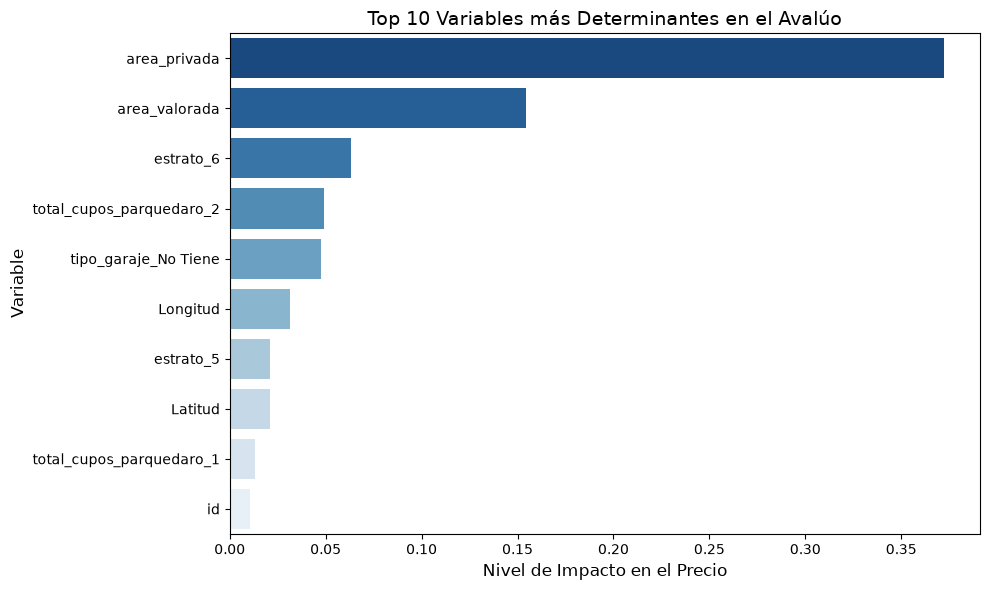

In [31]:

# 1. Extraer la importancia de cada variable desde el modelo entrenado
importancia = modelo_rf.feature_importances_
df_importancia = pd.DataFrame({'Variable': X_train.columns, 'Importancia': importancia})

# 2. Ordenar para obtener el Top 10
df_top10 = df_importancia.sort_values(by='Importancia', ascending=False).head(10)

print("--- Top 10 Variables que más dictan el precio ---")
for index, row in df_top10.iterrows():
    print(f"{row['Variable']}: {row['Importancia']:.4f}")

# 3. Visualizar el impacto para tu presentación
plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=df_top10, palette='Blues_r')
plt.title('Top 10 Variables más Determinantes en el Avalúo', fontsize=14)
plt.xlabel('Nivel de Impacto en el Precio', fontsize=12)
plt.ylabel('Variable', fontsize=12)
plt.tight_layout()
plt.show()

In [32]:
# 1. Corregir el dataset de entrenamiento quitando el 'id' ya que es un dato irrelevante para la predicción y puede confundir al modelo
if 'id' in X_train.columns:
    X_train = X_train.drop(columns=['id'])
    X_test = X_test.drop(columns=['id'])
    
# Reentrenar el modelo final limpio en el dataset completo para tener la mejor versión posible antes de predecir los datos de prueba
modelo_final = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
modelo_final.fit(X_train, y_train)

# 2. Aplicar la limpieza al dataset de Prueba (testeo)
# Rescatar las áreas
for col in ['area_valorada', 'area_privada']:
    if col in df_test.columns:
        df_test[col] = df_test[col].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

# Imputar nulos en prueba
for col in df_test.select_dtypes(include=['int64', 'float64']).columns:
    df_test[col] = df_test[col].fillna(df_test[col].median())
for col in df_test.select_dtypes(include=['object']).columns:
    df_test[col] = df_test[col].fillna('Sin_Dato')

# Codificar (One-Hot) y alinear columnas exactamente como en el entrenamiento
df_test_encoded = pd.get_dummies(df_test)
X_prediccion = df_test_encoded.reindex(columns=X_train.columns, fill_value=0)

# 3. Realizar las predicciones oficiales
predicciones_bancolombia = modelo_final.predict(X_prediccion)


In [33]:
from sklearn.metrics import mean_absolute_percentage_error
import numpy as np

# 1. Calcular la métrica MAPE (Mean Absolute Percentage Error) para evaluar el desempeño del modelo
mape = mean_absolute_percentage_error(y_test, predicciones)
print(f"--- Métrica Oficial Bancolombia ---")
print(f"Error Porcentual Absoluto Medio (MAPE): {mape:.2%}")

# 2. Generar el archivo CSV exactamente como lo exigen las instrucciones
entregable_oficial = pd.DataFrame({
    'id': df_test['id'] if 'id' in df_test.columns else range(len(predicciones_bancolombia)),
    'valor_total_avaluo': predicciones_bancolombia
})

ruta_oficial = '../data/base_evaluada.csv'
entregable_oficial.to_csv(ruta_oficial, index=False, sep=',')

print("\n--- ENTREGABLE FINALIZADO ---")
print(f"Archivo oficial generado en: {ruta_oficial}")

--- Métrica Oficial Bancolombia ---
Error Porcentual Absoluto Medio (MAPE): 21.79%

--- ENTREGABLE FINALIZADO ---
Archivo oficial generado en: ../data/base_evaluada.csv
